# CS688 Homework 4

Dataset: `person_knows_person.csv`.

This notebook covers Dijkstra and A* (2 points), Prim and Kruskal (2 points), PageRank and HITS (5 points), and ranking visualizations (6 points).

## Modeling decisions
- Each row identifies two connected people. Reciprocal rows are verified below and collapsed into one undirected edge.
- No edge weights are supplied. Each connection receives weight 1; shortest paths minimize hop count. MSTs consequently all have the same total weight, although their edges may differ.
- No coordinates or domain distance are supplied. A* uses the admissible zero heuristic, so this is not a demonstration of heuristic speedup.
- Rankings use the full graph. A reproducible connected subset is used only for readable visualization; displayed scores remain full-graph scores.
- NetworkX supplies the algorithm implementations. Confirm that library implementations are acceptable before submitting.


In [2]:
pip install pandas numpy networkx scipy matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 22.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display

DATA_PATH = Path("person_knows_person.csv")
SEED = 42


Python: 3.9.6
NetworkX: 3.2.1


## 1. Load and validate the data
The file is pipe-delimited and has two identically named headers. Rename them explicitly after loading.

In [5]:
edges = pd.read_csv(DATA_PATH, sep="|")
assert edges.shape[1] == 2, "Expected two node-ID columns."
edges.columns = ["source", "target"]
assert not edges.isna().any().any(), "Missing node IDs require review."
pairs = set(edges.itertuples(index=False, name=None))
reciprocal = all((v, u) in pairs for u, v in pairs)
assert reciprocal, "Review the directionality assumption: not all edges are reciprocal."
G = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.Graph())
nx.set_edge_attributes(G, 1, "weight")
assert nx.is_connected(G), "Select a connected component or explicitly use a spanning forest."
summary = pd.Series({
    "CSV rows": len(edges), "Nodes": G.number_of_nodes(),
    "Undirected edges": G.number_of_edges(),
    "Connected components": nx.number_connected_components(G),
    "Duplicate rows": int(edges.duplicated().sum()),
    "Self-loops": nx.number_of_selfloops(G),
    "All rows reciprocal": reciprocal,
})
display(edges.head(), summary.to_frame("Value"))


,source,target
0,38,956
1,38,962
2,38,941
3,38,74
4,38,36


,Value
CSV rows,29790
Nodes,998
Undirected edges,14895
Connected components,1
Duplicate rows,0
Self-loops,0
All rows reciprocal,True


## 2. Dijkstra and A*
Choose the smallest node ID as the source and a farthest reachable node as the target, breaking ties by node ID. This makes the example reproducible and avoids an arbitrary adjacent pair. Both algorithms use the same graph, endpoints, and weights.

In [6]:
source = min(G.nodes())
hops = nx.single_source_shortest_path_length(G, source)
target = min(node for node, distance in hops.items() if distance == max(hops.values()))
path_dijkstra = nx.dijkstra_path(G, source, target, weight="weight")
path_astar = nx.astar_path(G, source, target, heuristic=lambda u, v: 0, weight="weight")
def path_cost(path):
    return sum(G[u][v]["weight"] for u, v in zip(path, path[1:]))
shortest_results = pd.DataFrame([
    {"Algorithm": "Dijkstra", "Source": source, "Target": target,
     "Path": path_dijkstra, "Cost": path_cost(path_dijkstra)},
    {"Algorithm": "A* (h=0)", "Source": source, "Target": target,
     "Path": path_astar, "Cost": path_cost(path_astar)},
])
assert path_cost(path_dijkstra) == path_cost(path_astar) == hops[target]
display(shortest_results)


,Algorithm,Source,Target,Path,Cost
0,Dijkstra,0,2,"[0, 992, 296, 2]",3
1,A* (h=0),0,2,"[0, 992, 296, 2]",3


### Interpretation
Equal costs validate agreement on shortest-path length; paths need not be identical when alternatives tie. With unit weights, cost is the number of connections traversed. The zero heuristic deliberately makes A* behave like Dijkstra; no claim of faster search is justified here.

## 3. Prim and Kruskal
Each result is a new graph retaining only MST edges, satisfying the request to remove other edges without destroying the original graph needed for rankings.

In [7]:
mst_prim = nx.minimum_spanning_tree(G, algorithm="prim", weight="weight")
mst_kruskal = nx.minimum_spanning_tree(G, algorithm="kruskal", weight="weight")
mst_results = []
for name, tree in [("Prim", mst_prim), ("Kruskal", mst_kruskal)]:
    assert set(tree.nodes()) == set(G.nodes())
    assert nx.is_tree(tree)
    assert tree.number_of_edges() == G.number_of_nodes() - 1
    mst_results.append({"Algorithm": name, "Nodes": tree.number_of_nodes(),
        "Retained edges": tree.number_of_edges(),
        "Removed edges": G.number_of_edges() - tree.number_of_edges(),
        "Total weight": tree.size(weight="weight")})
assert mst_prim.size(weight="weight") == mst_kruskal.size(weight="weight")
display(pd.DataFrame(mst_results))


,Algorithm,Nodes,Retained edges,Removed edges,Total weight
0,Prim,998,997,13898,997.0
1,Kruskal,998,997,13898,997.0


### Interpretation
Because every edge has weight 1, every spanning tree has total weight V−1. Prim and Kruskal can choose different edges while remaining equally optimal. These MSTs simplify connectivity; they do not preserve all original shortest paths or ranking scores.

## 4. PageRank and HITS
PageRank uses damping 0.85. HITS uses the reciprocal directed representation of the graph and a deterministic starting vector. Hub and authority roles are not meaningfully distinct in this symmetric dataset; similarity is an expected modeling limitation, not evidence of an implementation error.

In [8]:
pagerank = nx.pagerank(G, alpha=0.85, weight="weight", max_iter=1000, tol=1e-12)
D = G.to_directed()
hubs, authorities = nx.hits(D, max_iter=1000, tol=1e-12,
                           nstart={node: 1.0 for node in D}, normalized=True)
rankings = pd.DataFrame({"PageRank": pagerank, "Hub": hubs, "Authority": authorities})
rankings.index.name = "Person ID"
assert np.isfinite(rankings.to_numpy()).all()
assert np.allclose(rankings.sum().to_numpy(), 1.0)
assert rankings.min().min() >= -1e-10
for metric in rankings.columns:
    print("Top 10:", metric)
    display(rankings.sort_values(metric, ascending=False).head(10))
print("Maximum absolute hub/authority difference:",
      float((rankings.Hub - rankings.Authority).abs().max()))
display(rankings.corr(method="spearman"))


Top 10: PageRank


,PageRank,Hub,Authority
Person ID,,,
959,0.003859,0.002287,0.002287
804,0.003683,0.002865,0.002865
721,0.003420,0.002802,0.002802
471,0.003373,0.002297,0.002297
983,0.003337,0.002749,0.002749
938,0.003332,0.002491,0.002491
973,0.003271,0.001953,0.001953
434,0.003165,0.002646,0.002646
40,0.003147,0.002279,0.002279


Top 10: Hub


,PageRank,Hub,Authority
Person ID,,,
366,0.002716,0.003358,0.003358
316,0.002832,0.003332,0.003332
811,0.003094,0.003310,0.003310
385,0.002837,0.003295,0.003295
107,0.002613,0.003221,0.003221
819,0.002605,0.003203,0.003203
918,0.002803,0.003180,0.003180
402,0.002698,0.003165,0.003165
240,0.002907,0.003162,0.003162


Top 10: Authority


,PageRank,Hub,Authority
Person ID,,,
366,0.002716,0.003358,0.003358
316,0.002832,0.003332,0.003332
811,0.003094,0.003310,0.003310
385,0.002837,0.003295,0.003295
107,0.002613,0.003221,0.003221
819,0.002605,0.003203,0.003203
918,0.002803,0.003180,0.003180
402,0.002698,0.003165,0.003165
240,0.002907,0.003162,0.003162


Maximum absolute hub/authority difference: 3.0357660829594124e-18


,PageRank,Hub,Authority
PageRank,1.000000,0.982641,0.982641
Hub,0.982641,1.000000,1.000000
Authority,0.982641,1.000000,1.000000


### Interpretation
PageRank distributes importance through links with damping; HITS jointly updates hub and authority scores. Compare the top-ranked IDs and the Spearman correlations above. Correlation measures agreement in ordering, not equality of score magnitudes. Do not infer real-world influence from anonymous simulated IDs.

## 5. Ranking and community visualizations

Use a connected 120-node breadth-first subset rooted at the highest-PageRank node, with sorted neighbor traversal. This selection emphasizes one neighborhood and is not a representative random sample. All displayed importance scores are calculated on the full graph.

The same layout is used for PageRank, hubs, and authorities. Darker blue and larger nodes indicate higher scores; colorbars use actual scores. Community membership is shown separately so it does not compete with the required rank-color encoding. Greedy modularity communities below are computed on the displayed subgraph only.


In [9]:
VIS_NODES = 120
root = rankings["PageRank"].idxmax()
selected = [root]
seen = {root}
for u, v in nx.bfs_edges(G, root, sort_neighbors=sorted):
    if v not in seen:
        selected.append(v)
        seen.add(v)
    if len(selected) >= min(VIS_NODES, G.number_of_nodes()):
        break
V = G.subgraph(selected).copy()
assert nx.is_connected(V)
print("Displayed nodes:", V.number_of_nodes(), "Displayed edges:", V.number_of_edges())


Displayed nodes: 120 Displayed edges: 667


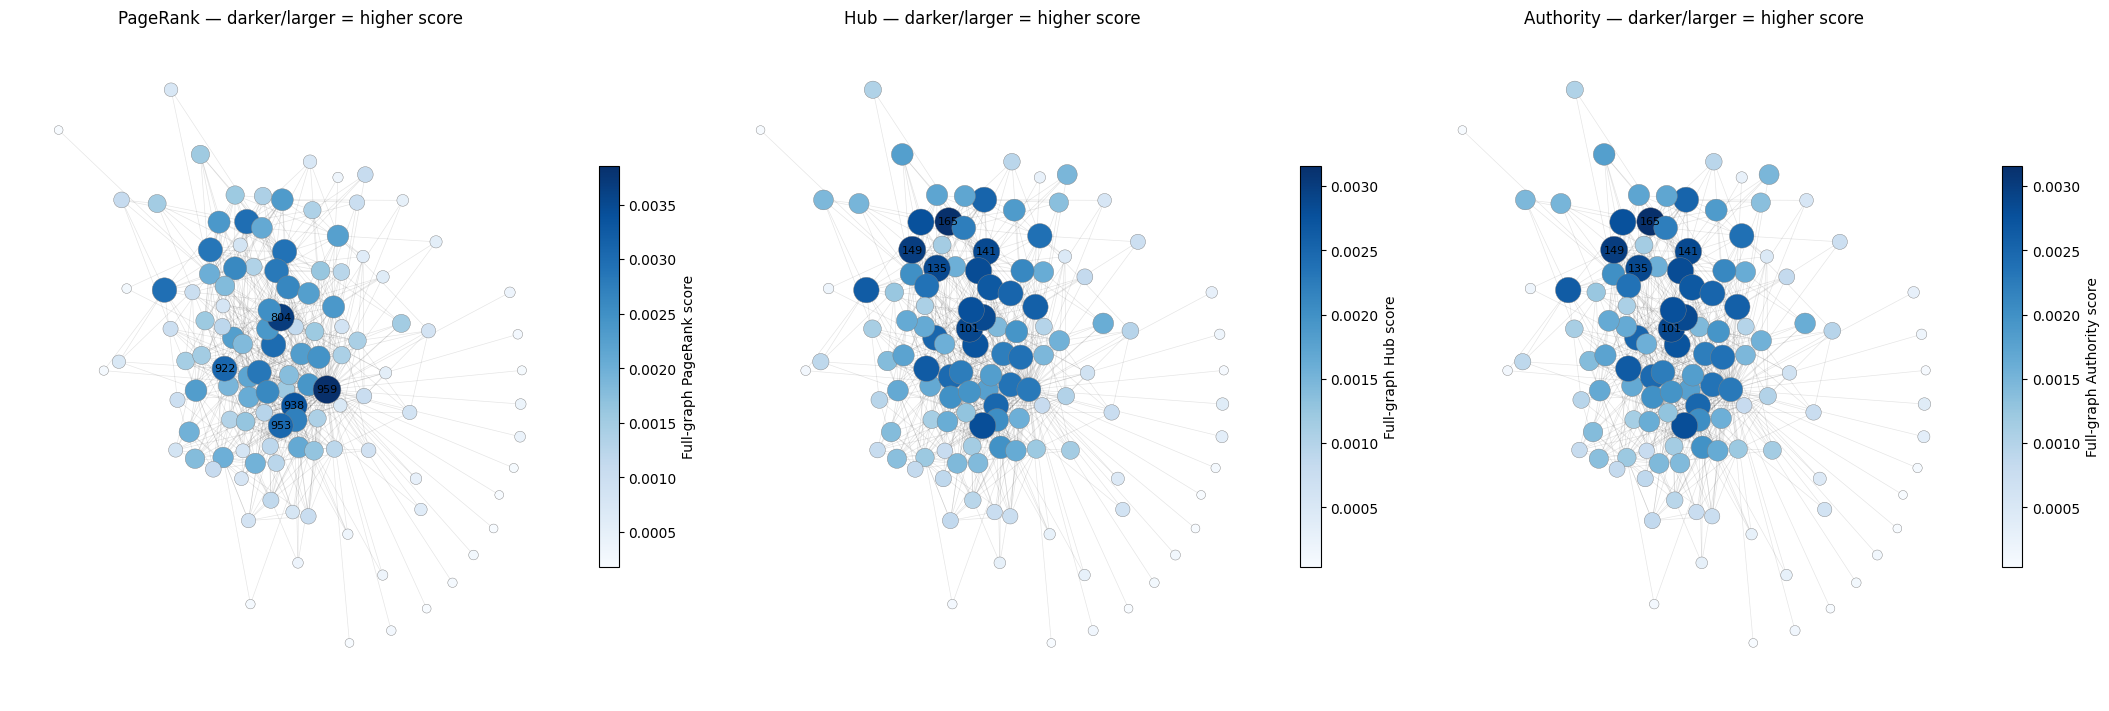

In [10]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

pos = nx.spring_layout(V, seed=SEED, iterations=100)
nodelist = list(V.nodes())
fig, axes = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)
for ax, metric in zip(axes, ["PageRank", "Hub", "Authority"]):
    values = rankings.loc[nodelist, metric].to_numpy()
    span = np.ptp(values)
    sizes = 40 + 360 * ((values - values.min()) / span if span else np.zeros_like(values))
    nx.draw_networkx_edges(V, pos, ax=ax, alpha=0.10, width=0.5)
    artist = nx.draw_networkx_nodes(V, pos, ax=ax, nodelist=nodelist,
        node_color=values, node_size=sizes, cmap="Blues",
        vmin=values.min(), vmax=values.max(), edgecolors="gray", linewidths=0.3)
    top = rankings.loc[nodelist].nlargest(5, metric).index
    nx.draw_networkx_labels(V, pos, ax=ax, labels={n: str(n) for n in top}, font_size=8)
    fig.colorbar(artist, ax=ax, shrink=0.6, label=f"Full-graph {metric} score")
    ax.set_title(metric + " — darker/larger = higher score")
    ax.axis("off")
plt.show()


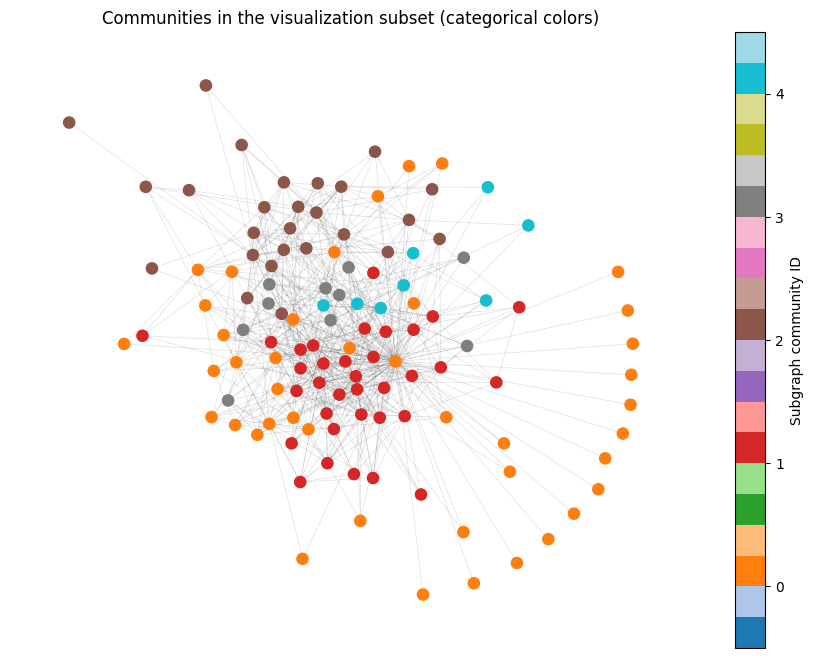

,Community,Nodes
0,0,42
1,1,34
2,2,26
3,3,10
4,4,8


In [11]:
communities = list(nx.community.greedy_modularity_communities(V, weight="weight"))
community_id = {node: i for i, group in enumerate(communities) for node in group}
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(V, pos, ax=ax, alpha=0.12, width=0.5)
artist = nx.draw_networkx_nodes(V, pos, ax=ax, nodelist=nodelist,
    node_color=[community_id[n] for n in nodelist], cmap="tab20", node_size=65,
    vmin=-0.5, vmax=max(len(communities)-0.5, 0.5))
fig.colorbar(artist, ax=ax, ticks=range(len(communities)), label="Subgraph community ID")
ax.set_title("Communities in the visualization subset (categorical colors)")
ax.axis("off")
plt.show()
display(pd.DataFrame({"Community": range(len(communities)),
                      "Nodes": [len(c) for c in communities]}))


## 6. Export and submission review

The exports retain the full rankings and the two MST edge lists. Review the numerical outputs and figures before submission. Add your own discussion identifying the highest-ranked nodes, agreements or differences across rankings, and what is lost by displaying only one neighborhood.

Checklist:
- Both shortest-path algorithms return a validated equal cost.
- Both MSTs span all nodes with V−1 edges and equal total weight.
- PageRank, hub, and authority rankings are reported separately.
- Ranking plots include darker high-ranked nodes and score colorbars.
- Unit weights, zero heuristic, reciprocal links, and visualization selection are disclosed.
- Confirm the instructor's policy on algorithm libraries and submission format.

Sources: supplied CS688 Homework 4 assignment and supplied `person_knows_person.csv`. Algorithm/visualization documentation consulted for design can be recorded here before submitting: NetworkX documentation (https://networkx.org/documentation/stable/) and Matplotlib colormap guidance (https://matplotlib.org/stable/users/explain/colors/colormaps.html).


In [12]:
EXPORT_DIR = Path("hw4_results")
EXPORT_DIR.mkdir(exist_ok=True)
rankings.sort_values("PageRank", ascending=False).to_csv(EXPORT_DIR / "node_rankings.csv")
shortest_results.to_csv(EXPORT_DIR / "shortest_paths.csv", index=False)
for name, tree in [("prim", mst_prim), ("kruskal", mst_kruskal)]:
    nx.to_pandas_edgelist(tree).to_csv(EXPORT_DIR / f"mst_{name}.csv", index=False)
print("Exported ranking, shortest-path, and MST tables.")


Exported ranking, shortest-path, and MST tables.
